<a href="https://colab.research.google.com/github/rbs3376/Projeto_mpg_1.0/blob/main/Projeto_mpg_linear_2_Completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 🚗 Projeto de Machine Learning — Previsão do consumo de combustível

O objetivo deste projeto é desenvolver um modelo de Machine Learning capaz de prever o consumo de combustível (mpg) de veículos a partir de características técnicas dos automóveis.

Objetivo

Este projeto tem como objetivo desenvolver modelos de Machine Learning capazes de prever o consumo de combustível de veículos utilizando o dataset mpg, disponível na biblioteca Seaborn.

A variável mpg será utilizada como variável alvo, representando o consumo do veículo em milhas por galão.

Serão desenvolvidos e comparados:

um modelo de regressão linear simples;
um modelo de regressão linear utilizando múltiplas variáveis;
um modelo Ridge, utilizando regularização.

Os modelos serão avaliados utilizando métricas de regressão e validação cruzada.

In [ ]:
# Importando as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Carregando o dataset nativo do seaborn "MPG"
df = sns.load_dataset("mpg")



### Conhecendo o dataset MPG

In [ ]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
df.shape


(398, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [ ]:
df.describe()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [ ]:
df.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


In [ ]:
df["cylinders"].value_counts()

,count
cylinders,
4,204
8,103
6,84
3,4
5,3


In [ ]:
df["origin"].value_counts()

,count
origin,
usa,249
japan,79
europe,70


In [ ]:
pd.crosstab(df["cylinders"],
            df["mpg"])

mpg,9.0,10.0,11.0,12.0,13.0,14.0,14.5,15.0,15.5,16.0,...,39.4,40.8,40.9,41.5,43.1,43.4,44.0,44.3,44.6,46.6
cylinders,,,,,,,,,,,,,,,,,,,,,
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,4,0,5,...,0,0,0,0,0,0,0,0,0,0
8,1,2,4,6,20,19,1,12,5,8,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.groupby("mpg")["origin"].describe()

,count,unique,top,freq
mpg,,,,
9.0,1,1,usa,1
10.0,2,1,usa,2
11.0,4,1,usa,4
12.0,6,1,usa,6
13.0,20,1,usa,20
...,...,...,...,...
43.4,1,1,europe,1
44.0,1,1,europe,1
44.3,1,1,europe,1


In [ ]:
df["model_year"].value_counts()

,count
model_year,
73,40
78,36
76,34
82,31
75,30
80,29
79,29
81,29
70,29


In [ ]:
df["name"].value_counts()

,count
name,
ford pinto,6
ford maverick,5
amc matador,5
toyota corolla,5
amc hornet,4
...,...
amc concord dl,1
volkswagen rabbit l,1
mazda glc custom l,1


Observações:
1.  O dataset possui 398 registros e 9 variáveis;
2.  O Target será a variável 'mpg';
3.  As demais serão avaliadas como possíveis variáveis explicativas;






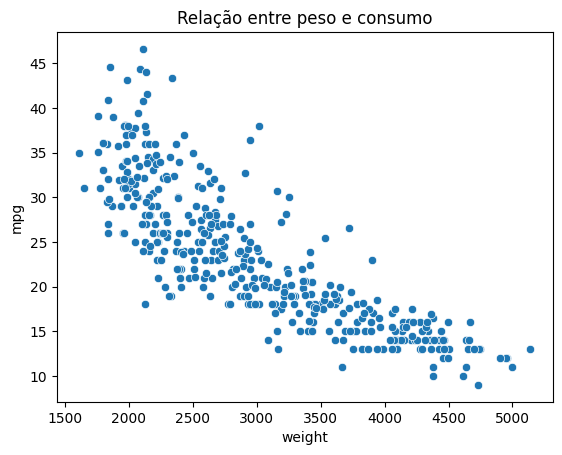

In [ ]:
sns.scatterplot(data=df, x="weight", y="mpg")
plt.title("Relação entre peso e consumo")
plt.show()

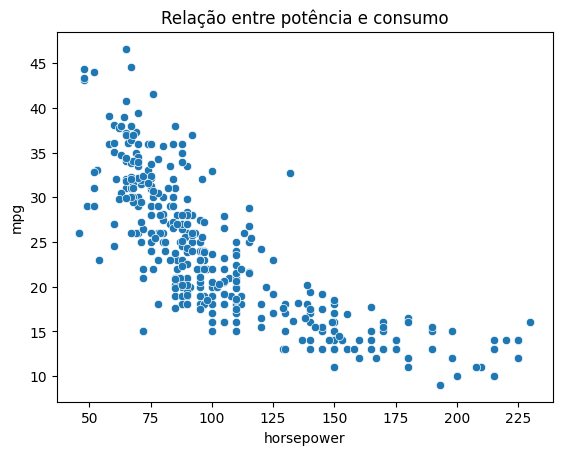

In [ ]:
sns.scatterplot(data=df, x="horsepower", y="mpg")
plt.title("Relação entre potência e consumo")
plt.show()

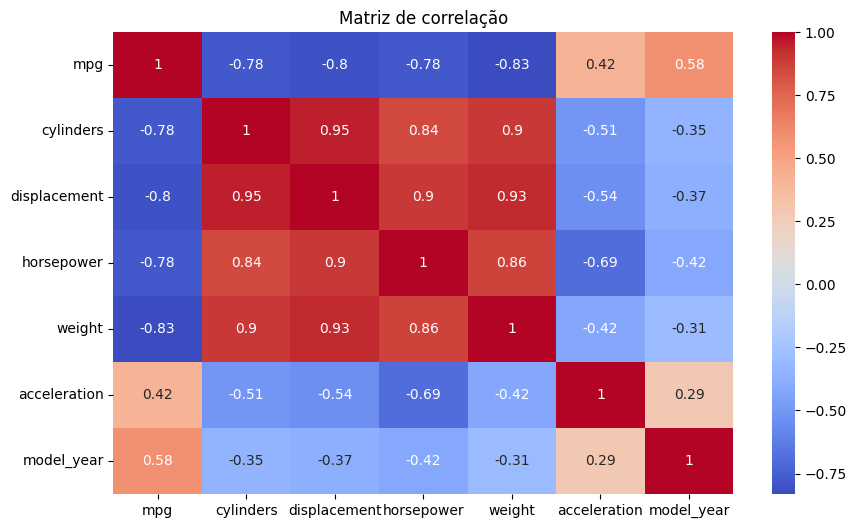

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes("number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Matriz de correlação")
plt.show()

Análise

A análise exploratória mostrou relações entre algumas características dos veículos e mpg. Variáveis como weight, horsepower, displacement e cylinders apresentam associação com o consumo.

Entretanto, associação entre variáveis não deve ser interpretada automaticamente como relação causal. Neste projeto, o objetivo é avaliar o poder preditivo dessas características.

Definição do problema

O problema foi definido como uma tarefa de aprendizado supervisionado de regressão.

In [ ]:
X = df.drop(columns=["mpg", "origin", "name" ], axis=1)
y = df["mpg"]

As variáveis 'origin' e 'name' não foram utilizadas nesta primeira configuração do modelo.




In [ ]:
# Importando a biblioteca de treino e teste
from sklearn.model_selection import train_test_split

Foram utilizados 75% dos dados para treinamento e 25% para teste. O parâmetro random_state=42 foi utilizado para garantir a reprodutibilidade da divisão.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

Foi utilizada uma divisão de:

75% para treinamento
25% para teste

O random_state=42 foi utilizado para garantir a reprodutibilidade da divisão.

In [ ]:
# Importando a bibliotecas do pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [ ]:
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # trata valores ausentes
    ("scaler", StandardScaler()), # Padroniza as variáveis numricas
    ("model", LinearRegression()) # Realiza a Regressão Linear
])

O dataset possui valores ausentes na variável horsepower.

O SimpleImputer substitui esses valores pela mediana.

O StandardScaler padroniza as variáveis numéricas.

O Pipeline mantém essas etapas organizadas e reduz o risco de data leakage, especialmente durante a validação cruzada.

In [ ]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LinearRegression())])

In [ ]:
y_pred_train = pipeline.predict(X_train)

In [ ]:
y_pred = pipeline.predict(X_test)

In [ ]:
# Importando as bibliotecas das métricas
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import cross_val_score

In [ ]:
print("Métricas de treino")

mae_train = mean_absolute_error(y_train, y_pred_train) # Erro absoluto médio das previsões.
mse_train = mean_squared_error(y_train, y_pred_train) # Expressa o erro quadratico médio.
rmse_train = np.sqrt(mse_train) # Raiz quadrada do MSE; dá maior peso a erros grandes.
mape_train = mean_absolute_percentage_error(y_train, y_pred_train) # Erro percentual absoluto médio.
r2_train = r2_score(y_train, y_pred_train) # Proporção da variabilidade do alvo explicada pelo modelo.

print(f"MAPE = {mape_train:.2f}")
print(f"MAE = {mae_train:.2f}")
print(f"RMSE = {rmse_train:.2f}")
print(f"R² = {r2_train:.2f}")
print(f"MSE = {mse_train:.2f}")


print("\nMétricas do conjunto de teste")

mae_test = mean_absolute_error(y_test, y_pred)
mse_test = mean_squared_error(y_test, y_pred)
rmse_test = np.sqrt(mse_test)
mape_test = mean_absolute_percentage_error(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)

print(f"MAPE = {mape_test:.2f}")
print(f"MAE = {mae_test:.2f}")
print(f"RMSE = {rmse_test:.2f}")
print(f"R² = {r2_test:.2f}")
print(f"MSE = {mse_test:.2f}")

Métricas de treino
MAPE = 0.12
MAE = 2.69
RMSE = 3.52
R² = 0.80
MSE = 12.41

Métricas do conjunto de teste
MAPE = 0.12
MAE = 2.53
RMSE = 3.13
R² = 0.83
MSE = 9.81


Os resultados obtidos nos conjuntos de treinamento e teste foram próximos. O R² foi de 0,80 no treinamento e 0,83 no teste, enquanto o RMSE foi de 3,52 e 3,13, respectivamente. Dessa forma, não foram observados sinais evidentes de overfitting nessa configuração.

In [ ]:
scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='r2')

A validação cruzada com cinco folds apresentou R² médio de aproximadamente 0,79 e baixo desvio padrão, indicando desempenho relativamente consistente entre as diferentes divisões do conjunto de treinamento.

In [ ]:
print(f"R² de cada fold: {scores}")
print(f"R² médio: {scores.mean():.2f}")
print(f"Desvio padrão: {scores.std():.4f}")

R² de cada fold: [0.81100918 0.77489188 0.7887446  0.79575329 0.77595793]
R² médio: 0.79
Desvio padrão: 0.0134


O modelo apresentou R² médio de aproximadamente 0,79 nas cinco divisões.

O baixo desvio padrão indica que os resultados dos folds foram relativamente próximos entre si.

### MODELO SIMPLES 'WEIGHT' X 'MPG'


In [ ]:
X_simple = df[["weight"]]
y_simple = df["mpg"]

In [ ]:
X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple,
    y_simple,
    test_size=0.25,
    random_state=42
)

In [ ]:
pipeline_simple = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [ ]:
pipeline_simple.fit(X_simple_train, y_simple_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LinearRegression())])

In [ ]:
y_simple_pred = pipeline_simple.predict(X_simple_test)
y_simple_pred_train = pipeline_simple.predict(X_simple_train)

In [ ]:

mae_simple = mean_absolute_error(y_simple_test, y_simple_pred)
mse_simple = mean_squared_error(y_simple_test, y_simple_pred)
rmse_simple = np.sqrt(mse_simple)
mape_simple = mean_absolute_percentage_error(y_simple_test, y_simple_pred)
r2_simple = r2_score(y_simple_test, y_simple_pred)

print(f"MAPE = {mape_simple:.2f}")
print(f"MAE = {mae_simple:.2f}")
print(f"RMSE = {rmse_simple:.2f}")
print(f"R² = {r2_simple:.2f}")
print(f"MSE = {mse_simple:.2f}")

MAPE = 0.15
MAE = 3.21
RMSE = 3.93
R² = 0.73
MSE = 15.46


In [ ]:
scores_simple = cross_val_score(pipeline_simple, X_simple_train, y_simple_train, cv=5, scoring='r2')

In [ ]:
print(f"R² de cada fold: {scores_simple}")
print(f"R² médio: {scores_simple.mean():.2f}")
print(f"Desvio padrão: {scores_simple.std():.4f}")

R² de cada fold: [0.6650693  0.64457429 0.68963461 0.7076516  0.65113421]
R² médio: 0.67
Desvio padrão: 0.0237


In [ ]:
print("Métricas de treino - modelo simples")

mae_simple_train = mean_absolute_error(
    y_simple_train,
    y_simple_pred_train
)

mse_simple_train = mean_squared_error(
    y_simple_train,
    y_simple_pred_train
)

rmse_simple_train = np.sqrt(mse_simple_train)

mape_simple_train = mean_absolute_percentage_error(
    y_simple_train,
    y_simple_pred_train
)

r2_simple_train = r2_score(
    y_simple_train,
    y_simple_pred_train
)

print(f"MAPE = {mape_simple_train:.2f}")
print(f"MAE = {mae_simple_train:.2f}")
print(f"RMSE = {rmse_simple_train:.2f}")
print(f"R² = {r2_simple_train:.2f}")
print(f"MSE = {mse_simple_train:.2f}")

Métricas de treino - modelo simples
MAPE = 0.15
MAE = 3.35
RMSE = 4.46
R² = 0.68
MSE = 19.92


O modelo completo apresentou desempenho preditivo superior ao modelo simples.

No conjunto de teste, o R² aumentou de 0,73 para 0,83, enquanto o RMSE diminuiu de 3,93 para 3,13.

A validação cruzada também apresentou resultado superior para o modelo completo, com R² médio de 0,79, contra 0,67 no modelo simples.

Os resultados indicam que a utilização conjunta das características selecionadas fornece informações preditivas adicionais em comparação com a utilização isolada de weight.

In [ ]:
from sklearn.linear_model import Ridge

In [ ]:
pipeline_ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

In [ ]:
pipeline_ridge.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', Ridge())])

In [ ]:
y_ridge_train = pipeline_ridge.predict(X_train)
y_ridge_test = pipeline_ridge.predict(X_test)

In [ ]:
print("Métricas de treino")
mae_ridge_train = mean_absolute_error(y_train, y_pred_train)
mse_ridge_train = mean_squared_error(y_train, y_pred_train)
rmse_ridge_train = np.sqrt(mse_train)
mape_ridge_train = mean_absolute_percentage_error(y_train, y_pred_train)
r2_ridge_train = r2_score(y_train, y_pred_train)

print(f"MAPE = {mape_ridge_train:.2f}")
print(f"MAE = {mae_ridge_train:.2f}")
print(f"RMSE = {rmse_ridge_train:.2f}")
print(f"R² = {r2_ridge_train:.2f}")
print(f"MSE = {mse_ridge_train:.2f}")

print("Métricas de teste")

mae_ridge_test = mean_absolute_error(y_test, y_ridge_test)
mse_ridge_test = mean_squared_error(y_test, y_ridge_test)
rmse_ridge_test = np.sqrt(mse_test)
mape_ridge_test = mean_absolute_percentage_error(y_test, y_ridge_test)
r2_ridge_test = r2_score(y_test, y_ridge_test)

print(f"MAPE = {mape_ridge_test:.2f}")
print(f"MAE = {mae_ridge_test:.2f}")
print(f"RMSE = {rmse_ridge_test:.2f}")
print(f"R² = {r2_ridge_test:.2f}")
print(f"MSE = {mse_ridge_test:.2f}")

Métricas de treino
MAPE = 0.12
MAE = 2.69
RMSE = 3.52
R² = 0.80
MSE = 12.41
Métricas de teste
MAPE = 0.12
MAE = 2.53
RMSE = 3.13
R² = 0.83
MSE = 9.81


In [ ]:
scores_ridge = cross_val_score(
    pipeline_ridge,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

In [ ]:
scores_ridge.mean()
scores_ridge.std()

np.float64(0.012386265946664577)

In [ ]:
print(f"R² de cada fold: {scores_ridge}")
print(f"R² médio: {scores_ridge.mean():.2f}")
print(f"Desvio padrão: {scores_ridge.std():.4f}")

R² de cada fold: [0.81085705 0.7754017  0.78806297 0.79536568 0.78070168]
R² médio: 0.79
Desvio padrão: 0.0124


Com alpha=1.0, o Ridge não apresentou mudança relevante no desempenho preditivo em comparação com a regressão linear.

Entretanto, houve alteração na magnitude de diversos coeficientes, característica da regularização.

In [ ]:
coef_linear = pipeline.named_steps["model"].coef_
coef_ridge = pipeline_ridge.named_steps["model"].coef_

comparacao_coef = pd.DataFrame({
    "variavel": X_train.columns,
    "linear_regression": coef_linear,
    "ridge": coef_ridge
})

comparacao_coef

,variavel,linear_regression,ridge
0,cylinders,0.205470,0.164046
1,displacement,-0.265473,-0.352111
2,horsepower,0.249696,0.160657
3,weight,-5.704598,-5.518831
4,acceleration,0.235778,0.187050
5,model_year,2.863873,2.839135


A regularização modificou os coeficientes do modelo, mas, com alpha=1.0, não produziu uma mudança relevante no desempenho preditivo.

Regularização com Ridge: foi aplicado o modelo Ridge com alpha=1.0, mantendo o mesmo conjunto de variáveis, divisão dos dados e processo de pré-processamento utilizado na regressão linear. Os resultados apresentaram desempenho praticamente equivalente ao modelo LinearRegression, com R² de 0,83 no conjunto de teste e R² médio de 0,79 na validação cruzada. Apesar da ausência de ganho relevante nas métricas preditivas, foi observada uma redução na magnitude de diversos coeficientes, característica da regularização Ridge.

### Boas Práticas
Data leakage

O pré-processamento foi colocado dentro do Pipeline e a validação cruzada foi realizada sobre o conjunto de treinamento, evitando que informações do conjunto de teste fossem utilizadas durante o treinamento.

Validação cruzada

Foi utilizada validação cruzada com 5 folds para avaliar a consistência do modelo.

PCA

Não foi aplicado PCA neste projeto porque o conjunto utilizado possui poucas variáveis numéricas e o objetivo principal é construir e interpretar um modelo de regressão, não reduzir uma dimensionalidade elevada.

Balanceamento de classes

Não foi aplicado balanceamento de classes porque este projeto é um problema de regressão, e não de classificação. A variável mpg é contínua.

Conclusão

Neste projeto foram desenvolvidos modelos de Machine Learning para previsão do consumo de combustível utilizando o dataset MPG.

Inicialmente foi desenvolvido um modelo simples utilizando apenas a variável weight. Posteriormente, foi desenvolvido um modelo completo utilizando múltiplas características dos veículos.

O modelo completo apresentou desempenho preditivo superior ao modelo simples. No conjunto de teste, apresentou R² de 0,83, contra 0,73 do modelo simples, além de apresentar menor MAE e RMSE. A validação cruzada também apresentou resultado superior para o modelo completo, com R² médio de 0,79, contra 0,67 no modelo simples.

A comparação entre treinamento e teste não apresentou evidências claras de overfitting nessa configuração experimental.

Também foi aplicado o modelo Ridge com alpha=1.0. Os resultados foram praticamente equivalentes aos obtidos pela Regressão Linear, apresentando R² de 0,83 no conjunto de teste e R² médio de 0,79 na validação cruzada. Apesar disso, foi observada alteração na magnitude de diversos coeficientes, demonstrando o efeito da regularização.

Dessa forma, para este conjunto de dados e configuração experimental, o modelo completo apresentou maior capacidade preditiva que o modelo simples, enquanto a regularização Ridge não proporcionou ganho relevante nas métricas de desempenho com o valor de alpha utilizado.

In [ ]:
resultado_final = pd.DataFrame({
    "Modelo": [
        "LinearRegression Simples",
        "LinearRegression Completo",
        "Ridge"
    ],
    "R2_Teste": [
        0.73,
        0.83,
        0.83
    ],
    "RMSE_Teste": [
        3.93,
        3.13,
        3.13
    ],
    "R2_CV": [
        0.67,
        0.79,
        0.79
    ]
})

resultado_final

,Modelo,R2_Teste,RMSE_Teste,R2_CV
0,LinearRegression Simples,0.73,3.93,0.67
1,LinearRegression Completo,0.83,3.13,0.79
2,Ridge,0.83,3.13,0.79
